# Session 3 - AI delegation and side-by-side audit

Same cleaning task given to two models, checked against my own cleaning from session 2 (the baseline).
Model code is pasted as is in the "Model" cells. If it crashes, I keep it in the log and leave `df_A1 = None` so the notebook still runs.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

## 0. My cleaning from session 2 (baseline)

- vehicle_type: lower case, electric_bike -> e-bike, trottinette -> scooter
- end_station_id empty: keep the trip, add outside_station
- duration: keep only 0 < duration < 1440 min (24 h)
- IQR outliers (k=1.5) on the clean durations: flagged, not removed

In [2]:
def clean(df):
    df = df.copy()
    print("raw:", len(df))

    df["vehicle_type"] = df["vehicle_type"].str.lower().replace({"electric_bike": "e-bike", "trottinette": "scooter"})
    df["outside_station"] = df["end_station_id"].isna()
    df["start_time"] = pd.to_datetime(df["start_time"])

    d = df["duration_minutes"]
    print("negative:", (d < 0).sum(), "| 24h or more:", (d >= 1440).sum())
    df = df[(d > 0) & (d < 1440)].copy()
    print("after duration filter:", len(df))

    q1, q3 = df["duration_minutes"].quantile([0.25, 0.75])
    iqr = q3 - q1
    df["duration_outlier"] = (df["duration_minutes"] < q1 - 1.5 * iqr) | (df["duration_minutes"] > q3 + 1.5 * iqr)
    print("IQR fences:", round(q1 - 1.5 * iqr, 1), round(q3 + 1.5 * iqr, 1), "| flagged:", df["duration_outlier"].sum())
    return df

The 7 checks of the grid, measured on the table the model returns (not on what it says in its answer).

In [3]:
def checks(df, n_raw=None):
    if df is None:
        return {}
    d = df["duration_minutes"]
    q1, q3 = d.quantile([0.25, 0.75])
    iqr = q3 - q1
    return {
        "raw rows": n_raw,
        "missing end_station_id": int(df["end_station_id"].isna().sum()),
        "flag column": "outside_station" in df.columns,
        "vehicle labels": df["vehicle_type"].nunique(),
        "negative durations left": int((d < 0).sum()),
        "24h or more left": int((d >= 1440).sum()),
        "rows after cleaning": len(df),
        "IQR flagged (k=1.5)": int(((d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)).sum()),
    }

## 1. Lyon baseline

In [4]:
raw_lyon = pd.read_csv("trips_lyon.csv")
print("missing end_station_id in raw:", raw_lyon["end_station_id"].isna().sum())
lyon = clean(raw_lyon)
base_lyon = checks(lyon, len(raw_lyon))
base_lyon

missing end_station_id in raw: 407
raw: 7000
negative: 109 | 24h or more: 96
after duration filter: 6795
IQR fences: -7.9 36.1 | flagged: 160


{'raw rows': 7000,
 'missing end_station_id': 397,
 'flag column': True,
 'vehicle labels': 3,
 'negative durations left': 0,
 '24h or more left': 0,
 'rows after cleaning': 6795,
 'IQR flagged (k=1.5)': 160}

Same numbers as session 2: 7,000 -> 6,795 rows, 3 labels, 160 IQR outliers.
Note: 10 of the 407 trips without end station also have an impossible duration, so 397 are left in the clean table.

## 2. Lyon - round 1 (framing v1)

Task prompt, same for both models:
> Audit trips_lyon.csv, list the problems you find, then write pandas code that cleans the file. Handle outliers and report the final row count.

### Model A - [name and version] (log entry 1)

In [5]:
# paste the model code here, unedited (it reads trips_lyon.csv)


df_A1 = None     # the model's cleaned table (usually df)
n_raw_A1 = None  # raw row count given by the model

### Model B - [name and version] (log entry 2)

In [6]:
# paste the model code here, unedited (it reads trips_lyon.csv)


df_B1 = None     # the model's cleaned table (usually df)
n_raw_B1 = None  # raw row count given by the model

### Grid round 1

In [7]:
grid1 = pd.DataFrame({"baseline": base_lyon,
                      "model A": checks(df_A1, n_raw_A1),
                      "model B": checks(df_B1, n_raw_B1)})
grid1

,baseline,model A,model B
raw rows,7000,NaN,NaN
missing end_station_id,397,NaN,NaN
flag column,True,NaN,NaN
vehicle labels,3,NaN,NaN
negative durations left,0,NaN,NaN
24h or more left,0,NaN,NaN
rows after cleaning,6795,NaN,NaN
IQR flagged (k=1.5),160,NaN,NaN


### Fixes

For each mismatch: find the line, fix it, check that the grid goes back to the baseline. Both versions go in the log.

In [8]:
# fix 1 - model ?, check: ...
# model:   ...
# mine:    ...

df_A1_fixed = None
df_B1_fixed = None

pd.DataFrame({"baseline": base_lyon,
              "A fixed": checks(df_A1_fixed, n_raw_A1),
              "B fixed": checks(df_B1_fixed, n_raw_B1)})

,baseline,A fixed,B fixed
raw rows,7000,NaN,NaN
missing end_station_id,397,NaN,NaN
flag column,True,NaN,NaN
vehicle labels,3,NaN,NaN
negative durations left,0,NaN,NaN
24h or more left,0,NaN,NaN
rows after cleaning,6795,NaN,NaN
IQR flagged (k=1.5),160,NaN,NaN


## 3. Lyon - round 2 (framing v2)

Same task prompt. The context note now has the business rules (0 < duration < 24 h, 3 vehicle types, empty end station = keep and flag).

### Model A (log entry 3)

In [9]:
# paste the model code here, unedited (it reads trips_lyon.csv)


df_A2 = None     # the model's cleaned table (usually df)
n_raw_A2 = None  # raw row count given by the model

### Model B (log entry 4)

In [10]:
# paste the model code here, unedited (it reads trips_lyon.csv)


df_B2 = None     # the model's cleaned table (usually df)
n_raw_B2 = None  # raw row count given by the model

### Grid round 2

In [11]:
grid2 = pd.DataFrame({"baseline": base_lyon,
                      "model A": checks(df_A2, n_raw_A2),
                      "model B": checks(df_B2, n_raw_B2)})
grid2

,baseline,model A,model B
raw rows,7000,NaN,NaN
missing end_station_id,397,NaN,NaN
flag column,True,NaN,NaN
vehicle labels,3,NaN,NaN
negative durations left,0,NaN,NaN
24h or more left,0,NaN,NaN
rows after cleaning,6795,NaN,NaN
IQR flagged (k=1.5),160,NaN,NaN


## 4. Charts (mine vs the models)

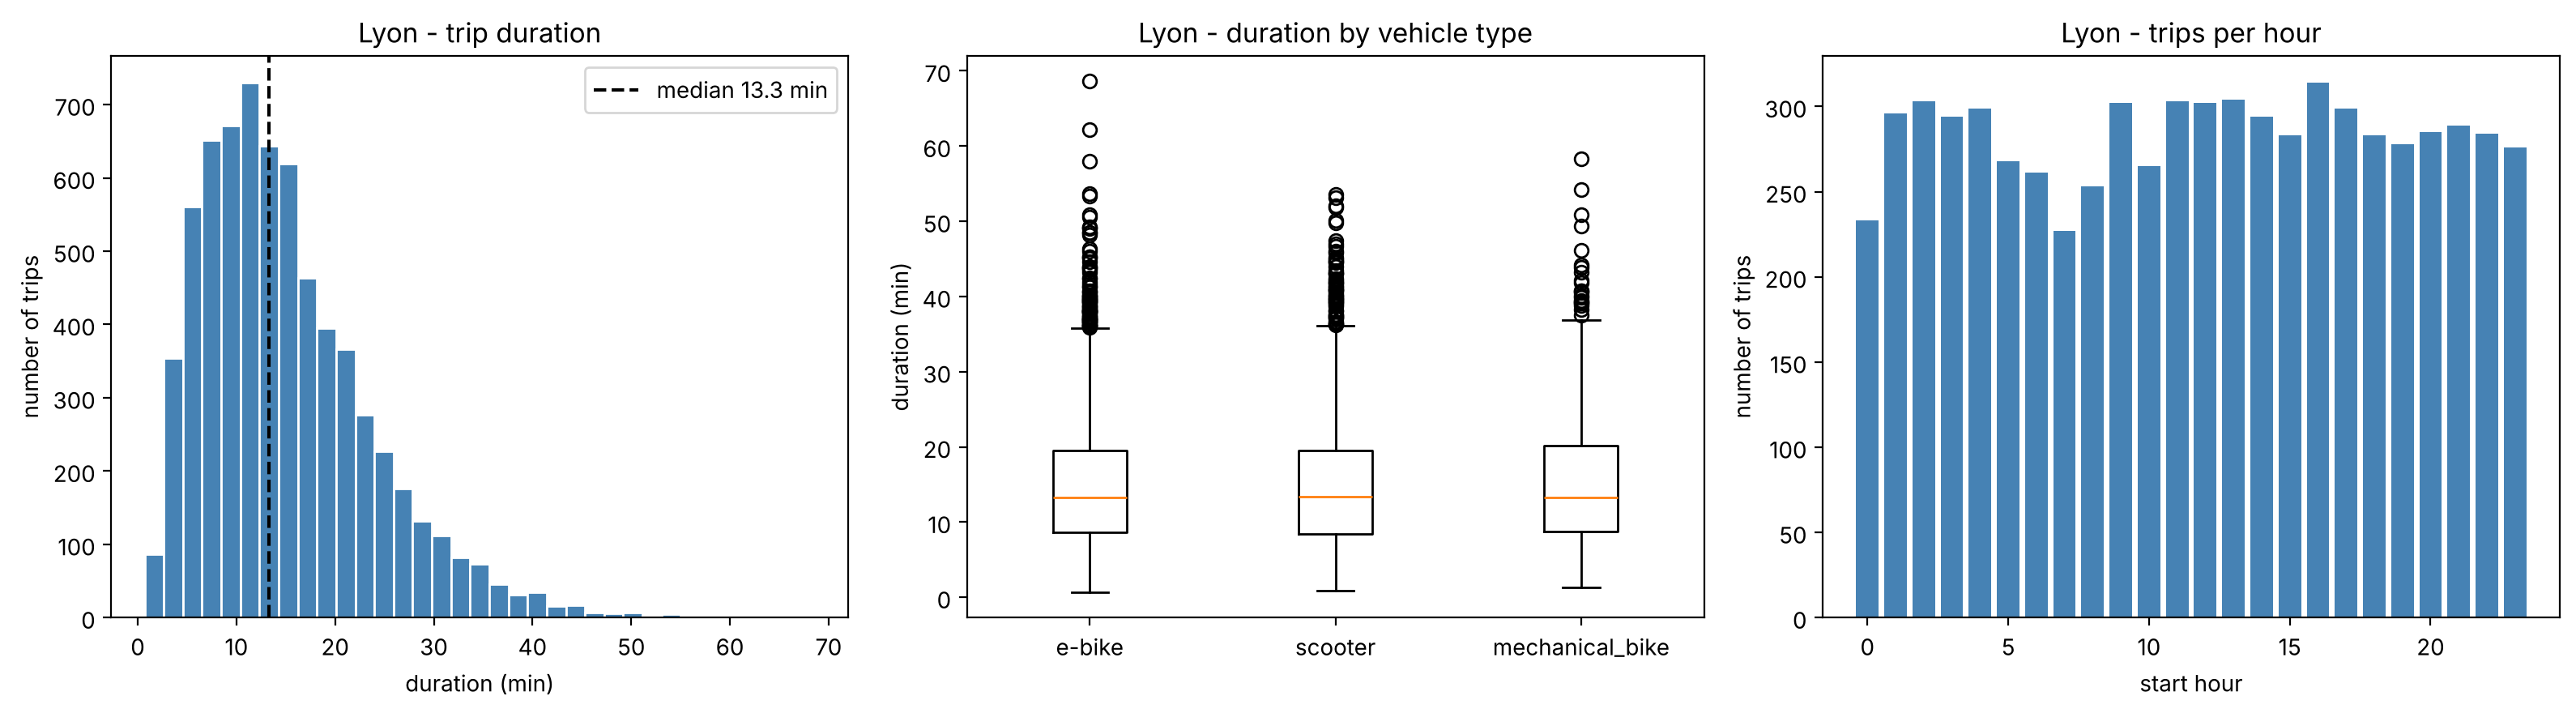

In [12]:
def charts(df, city):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

    ax[0].hist(df["duration_minutes"], bins=35, color="steelblue", edgecolor="white")
    ax[0].axvline(df["duration_minutes"].median(), color="black", linestyle="--",
                  label=f"median {df['duration_minutes'].median():.1f} min")
    ax[0].set(title=f"{city} - trip duration", xlabel="duration (min)", ylabel="number of trips")
    ax[0].legend()

    types = ["e-bike", "scooter", "mechanical_bike"]
    ax[1].boxplot([df.loc[df["vehicle_type"] == t, "duration_minutes"] for t in types], tick_labels=types)
    ax[1].set(title=f"{city} - duration by vehicle type", ylabel="duration (min)")

    per_hour = df["start_time"].dt.hour.value_counts().sort_index()
    ax[2].bar(per_hour.index, per_hour.values, color="steelblue")
    ax[2].set(title=f"{city} - trips per hour", xlabel="start hour", ylabel="number of trips")

    plt.tight_layout()
    plt.show()


charts(lyon, "Lyon")

What the charts show: durations are skewed to the right, most trips last between 5 and 25 min, median 13.3 min, longest 68.6 min. The 3 vehicle types have almost the same median (13.3 to 13.4 min). Trips per hour are almost flat (227 to 314 per hour), no rush hour peak, as many trips at 2 am as at 1 pm. Strange for a real service, so if a model writes "peaks in the morning and evening" it is describing what it expects, not the chart.

In [13]:
# model A charts (round 2)


In [14]:
# model B charts (round 2)


## 5. Paris - mini-challenge

Framing v2 reused, only the file name changes. Compared with my own Paris cleaning (same rules).

In [15]:
if os.path.exists("trips_paris.csv"):
    raw_paris = pd.read_csv("trips_paris.csv")
    print("missing end_station_id in raw:", raw_paris["end_station_id"].isna().sum())
    print(raw_paris["vehicle_type"].value_counts())
    print("battery outside [0, 100]:", (~raw_paris["battery_start_pct"].between(0, 100)).sum())
    print("duplicates:", raw_paris.duplicated().sum())
    paris = clean(raw_paris)
    base_paris = checks(paris, len(raw_paris))
else:
    print("trips_paris.csv not found")
    paris = None
    base_paris = {}
base_paris

trips_paris.csv not found


{}

### Model A (log entry 7)

In [16]:
# paste the model code here, unedited (it reads trips_paris.csv)


df_A3 = None     # the model's cleaned table (usually df)
n_raw_A3 = None  # raw row count given by the model

### Model B (log entry 8)

In [17]:
# paste the model code here, unedited (it reads trips_paris.csv)


df_B3 = None     # the model's cleaned table (usually df)
n_raw_B3 = None  # raw row count given by the model

### Grid Paris

In [18]:
grid_paris = pd.DataFrame({"baseline": base_paris,
                           "model A": checks(df_A3, n_raw_A3),
                           "model B": checks(df_B3, n_raw_B3)})
grid_paris

,baseline,model A,model B


In [19]:
if paris is not None:
    charts(paris, "Paris")

What the Paris charts show: ...

## 6. Conclusion

- closest model: ...
- safest model: ...
- what v2 changed: ...
- rule I would add after Paris: ...